# 18. 가짜 변화의 원인 진단 (실험 7 후속)

**한 줄 요약:** 실험 7에서 숲이 그대로인데 2022–23 사진과 2024–25 사진의 탄소가 지역 평균 1.28%p 달랐다(전부 같은 방향). 이 노트북은 **"여름 사진 탓인가, 겨울 사진 탓인가, 겨울이라면 눈 탓인가"**를 가린다.

**세 가지를 본다**
- **A. 어디가 달라졌나** (몇 분, 학습 없음) — 같은 픽셀의 38피처가 두 시기 사이에 얼마나 움직였나. 여름 묶음 / 겨울 묶음 / 차이 묶음
- **C. 눈·위성 확인** (GEE, 수 분–20분 [추정]) — 두 시기 겨울(11–12월, 1–2월)의 눈 비율, 장면 수, 위성(S2A·S2B·S2C) 구성
- **B. 바꿔 끼우기 시험** (본 판정, 약 2시간 [추정]) — 05와 똑같이 모델을 학습한 뒤, 2024–25 피처에서 **겨울 사진 부분만** 2022–23으로 바꿔 끼워 예측. 가짜 변화가 그대로 재현되면 범인은 겨울 사진. 여름만 바꾼 것도 같이 본다

**"모두 실행" 가능.** [2] 사전 기록에서 `CONFIRMED = True`로 바꾸기 전에는 멈춘다. [6]은 GEE 로그인 창이 뜰 수 있으니 처음에 자리에 있을 것. B는 폴드마다 저장하므로 끊기면 다시 "모두 실행".

**필요한 파일 (모두 Drive에 있음):** `{지역}_s05.npz`, `{지역}_old.npz`, `exp7_results.npz`, `exp4c_folds/`, v1 영상 `data/s2/{지역}_s2_20band.tif`(격자 읽기용)

In [3]:
# [1] 설정
!pip install -q rasterio earthengine-api

import os, json, time, gc, warnings
import numpy as np
import pandas as pd
import rasterio
from scipy.stats import spearmanr
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt
from google.colab import drive
warnings.filterwarnings('ignore', category=RuntimeWarning)

drive.mount('/content/drive')
D        = '/content/drive/MyDrive/forest/data'
OUT      = '/content/drive/MyDrive/forest/outputs'
FOLD_DIR = f'{OUT}/exp18_folds'
PR_PATH  = f'{OUT}/exp18_prereg.json'
GEE_JSON = f'{OUT}/exp18_gee.json'
os.makedirs(FOLD_DIR, exist_ok=True)
PROJECT_ID = 'driven-era-467023-m3'

TRAIN_REGIONS = ['inje', 'hongcheon', 'gangneung', 'pyeongchang',
                 'bonghwa', 'geumsan', 'geochang', 'suncheon']
KO = {'inje': '인제', 'hongcheon': '홍천', 'gangneung': '강릉', 'pyeongchang': '평창',
      'bonghwa': '봉화', 'geumsan': '금산', 'geochang': '거창', 'suncheon': '순천'}

C    = {1: 79.25, 2: 101.02, 3: 92.01}          # 확정계수만 (구계수 금지)
SEEDS              = [16, 17, 18, 19, 20]
N_TRAIN_PER_REGION = 30_000
RF_PARAMS = dict(n_estimators=80, min_samples_leaf=20, max_features='sqrt',
                 class_weight='balanced', n_jobs=-1)       # 05와 동일

NEW = ('2024-01-01', '2025-12-31')    # v1 (05)
OLD = ('2022-01-01', '2023-12-31')    # 16번

# 피처 묶음 (4절 번호). 여름만 쓰는 것 / 겨울만 쓰는 것 / 둘 다 쓰는 것
S_COLS = list(range(0, 10)) + [20, 22, 26, 27, 28, 29]     # 여름 밴드, s_ndvi, s_ndmi, s_ndvi 주변 통계
W_COLS = list(range(10, 20)) + [21, 23, 30, 31, 32, 33]    # 겨울 밴드, w_ndvi, w_ndmi, w_ndvi 주변 통계
D_COLS = [24, 25, 34, 35, 36, 37]                          # 여름−겨울 차이와 그 주변 통계
D_SD   = [35, 37]                                          # 차이의 주변 표준편차 — 두 시기로 정확히 다시 만들 수 없음
assert sorted(S_COLS + W_COLS + D_COLS) == list(range(38))

for r in TRAIN_REGIONS:
    for f in (f'{OUT}/{r}_s05.npz', f'{OUT}/{r}_old.npz', f'{D}/s2/{r}_s2_20band.tif'):
        assert os.path.exists(f), f'없음: {f}'
assert os.path.exists(f'{OUT}/exp7_results.npz'), '17번 결과(exp7_results.npz)가 없음'
print('파일 확인 완료')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
파일 확인 완료


In [4]:
# [2] 사전 기록 — 결과를 보기 전에 확정. CONFIRMED = True 로 바꿔야 진행된다
CONFIRMED = True

PREREG = {
    'date': time.strftime('%Y-%m-%d %H:%M'),
    'question': ('실험 7의 가짜 변화(숲이 그대로인데 2022–23 vs 2024–25 사진으로 계산한 탄소 차이, '
                 '지역 |Δ| 평균 1.28%p, 전부 + 방향)는 여름 사진과 겨울 사진 중 어디에서 오는가. '
                 '겨울이라면 눈 차이와 맞는가'),
    'state_before': '17번 결과(exp7_results.npz, exp7_by_region.csv)만 봄. 이 노트북의 A·B·C 결과는 보지 않음',

    'design_B': ('05와 같은 LORO 40폴드(같은 학습 표본·RF·시드). 평가 = 17과 같은 픽셀(2022–23 값 있음 & Hansen lossyear < 22). '
                 '같은 모델로 6가지 입력 예측: 2024–25 / 2022–23 / '
                 'W(여름 2024–25 + 겨울 2022–23) / S(여름 2022–23 + 겨울 2024–25) / 2022–23 재구성(검산). '
                 '차이 피처 24·25·34·36은 바꿔 끼운 값으로 다시 계산(평균 필터는 선형이라 정확). '
                 '35·37(차이의 주변 표준편차)은 정확히 못 만들어 두 가지로: a = 2024–25 값 유지, b = 2022–23 값 사용'),
    'definitions': ('Δ_full = 오차(2024–25) − 오차(2022–23) [17과 같은 정의]. '
                    'Δ_W = 오차(2024–25) − 오차(W): 겨울만 바꿨을 때 생기는 변화. Δ_S 도 같은 식. '
                    '설명률 E_X = 1 − Σ_지역|Δ_full − Δ_X| / Σ_지역|Δ_full| (분모는 8곳 |Δ| 합, 약 10%p → 0 근처가 아님)'),

    'rule_main': ('겨울 주원인 = E_W ≥ 0.6 이 5/5 시드에서, a·b 두 가지 모두 성립. '
                  '여름 주원인 = E_S ≥ 0.6 이 같은 조건. 둘 다 아니면 "한쪽으로 안 갈림". '
                  '0.6 근거: 두 효과가 더해지는 구조면 E_W + E_S ≈ 1 이므로 0.6 이상은 분명한 다수'),
    'rule_snow': ('눈 차이 있음 = 가짜 변화가 큰 지역(17의 5시드 평균 Δ_full ≥ +1.0: 인제·홍천·금산·거창·순천) 중 '
                  '4곳 이상에서 겨울(11–2월) 숲 픽셀 중 "눈 우세 픽셀"(유효 관측 중 눈(SCL 11) 비율 > 50%) 비율의 '
                  '시기 차이 |신−구| ≥ 2%p 이고, 그 4곳 이상의 부호가 같음. '
                  '근거: 중앙값 합성에서 눈이 값을 바꾸려면 관측의 절반 이상이 눈이어야 함. '
                  '17에서 침엽 예측 비율이 8–14%p 바뀐 지역이 있으므로 눈 탓이라면 최소 수 %p 차이가 있어야 함. '
                  '방향(눈이 침엽/활엽 어느 쪽으로 미는지)은 확인된 바 없어 미리 정하지 않음'),
    'record_only': ['A: 피처 묶음별 이동(표준화 중앙값 차이), 지역 8곳 중 겨울 묶음 > 여름 묶음인 곳 수',
                    'A: 침엽·활엽 픽셀별 w_ndvi·s_ndvi 이동, Δ_full과의 순위상관(n=8)',
                    'C: 11–12월 / 1–2월 눈 비율, 장면 수, 위성 구성(S2A·S2B·S2C), 여름 장면 수',
                    'B: 더하기 검사 — Σ|Δ_full − (Δ_W + Δ_S)| / Σ|Δ_full|',
                    'B: 침엽 예측 비율 변화'],
    'predictions_추정': ['① 겨울 주원인 성립 (67절 1순위 용의자)',
                         '② 눈 규칙은 성립하지 않을 수 있음 — 남부(순천·거창·금산)도 Δ가 큰데 겨울 눈이 적을 것',
                         '③ 2024–25 합성에는 Sentinel-2C 장면이 섞여 있고 2022–23에는 없음'],
    'next_step': {
        '겨울 주원인 + 눈 차이 있음': 'R1: 19 = 2022–23 계절 5장 데이터(1–2월 없음), 20 = 1–2월 없는 모델로 연도 시험',
        '겨울 주원인 + 눈 차이 없음': ('R1은 그대로 첫 시험(1–2월 빼면 겨울 정보가 11–12월로 바뀜). '
                                     '단 C에서 위성 구성이 크게 다르면 R3(S2C 뺀 2024–25 합성) 먼저 검토'),
        '여름 주원인': '1–2월 문제 아님 → R1 효과 기대 낮음. 여러 해 합성 등 새 설계(별도 사전 기록)',
        '한쪽으로 안 갈림': '두 계절 모두 흔들림 → 해마다 같이 바뀌는 요인(위성·처리) 쪽. R3, 여러 해 합성 검토',
    },
    'seeds': SEEDS, 'carbon_coeff': C,
    'rf': {k: v for k, v in RF_PARAMS.items() if k != 'n_jobs'},
    'checks': ['폴드마다 2024–25 전체 오차 = 09 carb0 (0.01%p)', '평가 픽셀 수 = 17 n_eval',
               '2024–25·2022–23 평가 오차 = 17 new_eh·old_eh (0.01%p)', '2022–23 재구성 오차 = 2022–23 오차 (0.02%p)',
               '차이 피처 재계산식 검산 (오차 1e-4 이하)'],
}

if os.path.exists(PR_PATH):
    print('저장된 사전 기록 (덮어쓰지 않음):\n')
    print(json.dumps(json.load(open(PR_PATH, encoding='utf-8')), ensure_ascii=False, indent=1))
else:
    assert CONFIRMED, '사전 기록을 읽고 CONFIRMED = True 로 바꾼 뒤 다시 실행하세요 (정상 정지)'
    json.dump(PREREG, open(PR_PATH, 'w', encoding='utf-8'), ensure_ascii=False, indent=1)
    print('사전 기록 저장:', PR_PATH)

사전 기록 저장: /content/drive/MyDrive/forest/outputs/exp18_prereg.json


In [5]:
# [3] 함수
CVEC = np.array([C[1], C[2], C[3]])

def carbon_sum(y):
    return float(sum((y == v).sum() * C[v] for v in (1, 2, 3)))

def carbon_err(y_true, y_pred):
    t = carbon_sum(y_true)
    return (carbon_sum(y_pred) - t) * 100 / t

def hybrid(Xs_src, Xw_src, sd_src):
    # 여름 피처는 Xs_src, 겨울 피처는 Xw_src에서. 차이 피처는 다시 계산, 차이의 주변 sd(35·37)는 sd_src에서
    H = np.empty_like(Xs_src)
    H[:, S_COLS] = Xs_src[:, S_COLS]
    H[:, W_COLS] = Xw_src[:, W_COLS]
    H[:, 24] = H[:, 20] - H[:, 21]      # d_ndvi
    H[:, 25] = H[:, 22] - H[:, 23]      # d_ndmi
    H[:, 34] = H[:, 26] - H[:, 30]      # d_ndvi 5x5 평균 = 여름 평균 − 겨울 평균 (선형 필터)
    H[:, 36] = H[:, 28] - H[:, 32]      # d_ndvi 15x15 평균
    H[:, D_SD] = sd_src[:, D_SD]
    return H

def d_identity_err(X):
    # 캐시 값이 위 재계산식과 맞는지 (맞아야 hybrid가 의미 있음)
    return max(np.abs(X[:, 24] - (X[:, 20] - X[:, 21])).max(),
               np.abs(X[:, 25] - (X[:, 22] - X[:, 23])).max(),
               np.abs(X[:, 34] - (X[:, 26] - X[:, 30])).max(),
               np.abs(X[:, 36] - (X[:, 28] - X[:, 32])).max())
print('함수 정의 완료')

함수 정의 완료


In [6]:
# [4] 캐시 읽기 + 검산 (17과 같은 평가 픽셀인지, 재계산식이 맞는지)
S, O, MASK = {}, {}, {}
E7 = np.load(f'{OUT}/exp7_results.npz')
assert [str(x) for x in E7['regions']] == TRAIN_REGIONS, E7['regions']
assert [int(x) for x in E7['seeds']] == SEEDS, E7['seeds']

for j, r in enumerate(TRAIN_REGIONS):
    z = np.load(f'{OUT}/{r}_s05.npz')
    o = np.load(f'{OUT}/{r}_old.npz')
    S[r] = dict(X=z['X'], y=z['y'])
    assert len(o['y']) == len(z['y']) and (o['y'] == z['y']).all(), f'{r}: s05와 old 픽셀 순서 다름'
    O[r] = dict(X=o['X'])
    MASK[r] = o['ok'] & (o['loss'] < 22)
    n7 = int(round(float(E7['n_eval'][0, j])))
    assert int(MASK[r].sum()) == n7, f'{r}: 평가 픽셀 {int(MASK[r].sum()):,} ≠ 17의 {n7:,} — 멈추고 보고'
    e1 = d_identity_err(S[r]['X'][:100_000])
    e2 = d_identity_err(O[r]['X'][MASK[r]][:100_000])
    assert max(e1, e2) < 1e-4, f'{r}: 차이 피처 재계산식 불일치 ({e1:.1e}, {e2:.1e}) — 멈추고 보고'
    print(f'{KO[r]:4s} 평가 픽셀 {n7:>8,}  재계산식 오차 2024–25 {e1:.1e} / 2022–23 {e2:.1e}')

DH = E7['dh']          # (시드, 지역) 17의 Δ_full (딱 자르기)
DH_MEAN = DH.mean(0)
print('\n검산 통과 — 17과 같은 평가 픽셀, 차이 피처 재계산 가능')

인제   평가 픽셀  594,908  재계산식 오차 2024–25 1.2e-07 / 2022–23 1.2e-07
홍천   평가 픽셀  589,606  재계산식 오차 2024–25 1.2e-07 / 2022–23 1.2e-07
강릉   평가 픽셀  594,999  재계산식 오차 2024–25 1.2e-07 / 2022–23 1.2e-07
평창   평가 픽셀  588,860  재계산식 오차 2024–25 1.2e-07 / 2022–23 1.2e-07
봉화   평가 픽셀  593,974  재계산식 오차 2024–25 1.2e-07 / 2022–23 1.2e-07
금산   평가 픽셀  577,704  재계산식 오차 2024–25 1.2e-07 / 2022–23 1.2e-07
거창   평가 픽셀  581,663  재계산식 오차 2024–25 1.2e-07 / 2022–23 1.2e-07
순천   평가 픽셀  593,217  재계산식 오차 2024–25 8.9e-08 / 2022–23 8.9e-08

검산 통과 — 17과 같은 평가 픽셀, 차이 피처 재계산 가능


In [7]:
# [5] A. 어디가 달라졌나 (학습 없음, 몇 분)
#   z = (2022–23 중앙값 − 2024–25 중앙값) / 2024–25 표준편차  — 피처마다, 지역마다
FN = ([f's_{b}' for b in ['B2','B3','B4','B5','B6','B7','B8','B8A','B11','B12']]
      + [f'w_{b}' for b in ['B2','B3','B4','B5','B6','B7','B8','B8A','B11','B12']]
      + ['s_ndvi','w_ndvi','s_ndmi','w_ndmi','d_ndvi','d_ndmi',
         's_mu5','s_sd5','s_mu15','s_sd15','w_mu5','w_sd5','w_mu15','w_sd15',
         'd_mu5','d_sd5','d_mu15','d_sd15'])

Z, rows = {}, []
for j, r in enumerate(TRAIN_REGIONS):
    m = MASK[r]
    Xn, Xo, y = S[r]['X'][m], O[r]['X'][m], S[r]['y'][m]
    z = (np.median(Xo, 0) - np.median(Xn, 0)) / (Xn.std(0) + 1e-8)
    Z[r] = z
    row = dict(region=KO[r], dh_17=DH_MEAN[j],
               S_묶음=np.abs(z[S_COLS]).mean(), W_묶음=np.abs(z[W_COLS]).mean(), D_묶음=np.abs(z[D_COLS]).mean())
    for cls, nm in ((1, '침엽'), (2, '활엽')):
        c = y == cls
        row[f'{nm}_w_ndvi_이동'] = np.median(Xo[c, 21]) - np.median(Xn[c, 21])
        row[f'{nm}_s_ndvi_이동'] = np.median(Xo[c, 20]) - np.median(Xn[c, 20])
    rows.append(row)
    del Xn, Xo

A = pd.DataFrame(rows).set_index('region')
A.to_csv(f'{OUT}/exp18_A_shift.csv')
pd.DataFrame(Z, index=FN).rename(columns=KO).to_csv(f'{OUT}/exp18_A_z_by_feature.csv')
print('묶음 값 = 표준화 이동 크기 평균 (클수록 많이 달라짐). 이동 = 2022–23 − 2024–25 (NDVI 단위)\n')
print(A.round(3).to_string())

nW = int((A['W_묶음'] > A['S_묶음']).sum())
print(f'\n[기록] 겨울 묶음 이동 > 여름 묶음 이동: {nW}/8곳')
for col in ['침엽_w_ndvi_이동', '활엽_w_ndvi_이동', '침엽_s_ndvi_이동', '활엽_s_ndvi_이동']:
    print(f'[기록] 순위상관(Δ_17, {col}) = {spearmanr(A["dh_17"], A[col]).correlation:+.2f}  (n=8)')
top = pd.Series(np.mean([np.abs(Z[r]) for r in TRAIN_REGIONS], 0), index=FN).sort_values(ascending=False)
print('\n[기록] 8곳 평균 |z| 상위 8개 피처:\n' + top.head(8).round(3).to_string())

묶음 값 = 표준화 이동 크기 평균 (클수록 많이 달라짐). 이동 = 2022–23 − 2024–25 (NDVI 단위)

        dh_17   S_묶음   W_묶음   D_묶음  침엽_w_ndvi_이동  침엽_s_ndvi_이동  활엽_w_ndvi_이동  활엽_s_ndvi_이동
region                                                                                    
인제      2.958  0.274  0.083  0.005         0.002        -0.011        -0.017        -0.009
홍천      1.948  0.170  0.140  0.065         0.003        -0.006        -0.015         0.000
강릉      0.127  0.235  0.097  0.086        -0.021         0.008         0.001         0.005
평창     -0.058  0.143  0.181  0.104         0.013         0.003         0.017         0.011
봉화      0.550  0.309  0.169  0.118        -0.063        -0.029        -0.033        -0.013
금산      1.550  0.253  0.158  0.139        -0.037        -0.019        -0.040        -0.014
거창      1.445  0.299  0.142  0.093        -0.047        -0.033        -0.020        -0.011
순천      1.610  0.290  0.178  0.082        -0.023        -0.013        -0.023        -0.015

[기록] 겨울 묶음 이동 > 여름 묶음

In [8]:
# [6] C. 눈·위성 확인 (GEE). 처음 실행 때 로그인 창이 뜰 수 있음. 결과는 exp18_gee.json에 저장 → 다시 실행하면 건너뜀
import ee
try:
    ee.Initialize(project=PROJECT_ID)
except Exception:
    ee.Authenticate(); ee.Initialize(project=PROJECT_ID)

HANSEN_IDS = ['UMD/hansen/global_forest_change_2024_v1_12', 'UMD/hansen/global_forest_change_2025_v1_13',
              'UMD/hansen/global_forest_change_2023_v1_11']
def hansen():
    for hid in HANSEN_IDS:
        try:
            img = ee.Image(hid); img.bandNames().getInfo(); return img
        except Exception:
            continue
    raise RuntimeError('Hansen 자료를 찾지 못함 — 멈추고 보고')
HZ = hansen()

WINDOWS = {'w1112': [11, 12], 'w0102': [1, 2], 'leafoff': [11, 12, 1, 2], 'summer': [6, 7, 8, 9]}

def v1_grid(name):
    with rasterio.open(f'{D}/s2/{name}_s2_20band.tif') as s:
        return dict(crs=f'EPSG:{s.crs.to_epsg()}', b=s.bounds)

def gee_stats(name, period):
    g = v1_grid(name); b = g['b']
    aoi = ee.Geometry.Rectangle([b.left, b.bottom, b.right, b.top], proj=g['crs'], geodesic=False)
    forest = HZ.select('treecover2000').gte(50).And(HZ.select('lossyear').unmask(0).eq(0))
    bands, meta = [], {}
    for wn, months in WINDOWS.items():
        mf  = ee.Filter.Or([ee.Filter.calendarRange(m, m, 'month') for m in months])
        col = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED').filterBounds(aoi)
               .filterDate(*period).filter(mf).filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 50)))
        def obs(img):
            scl = img.select('SCL')
            valid = scl.neq(3).And(scl.neq(8)).And(scl.neq(9)).And(scl.neq(10))   # v1 cloud_mask와 같은 기준
            return valid.rename('v').addBands(scl.eq(11).rename('s')).toFloat()
        ss    = col.map(obs).sum()
        share = ss.select('s').divide(ss.select('v').max(1))
        bands += [share.rename(f'{wn}_snow'), share.gt(0.5).rename(f'{wn}_major'), ss.select('v').rename(f'{wn}_nvalid')]
        meta[wn] = ee.Dictionary(dict(n=col.size(), sat=col.aggregate_histogram('SPACECRAFT_NAME')))
    img = ee.Image.cat(bands).updateMask(forest)
    red = img.reduceRegion(ee.Reducer.mean(), aoi, scale=100, crs=g['crs'], maxPixels=1e9,
                           bestEffort=True, tileScale=4)
    return ee.Dictionary(dict(stats=red, meta=ee.Dictionary(meta))).getInfo()

gee = json.load(open(GEE_JSON)) if os.path.exists(GEE_JSON) else {}
for r in TRAIN_REGIONS:
    for pn, per in (('new', NEW), ('old', OLD)):
        key = f'{r}|{pn}'
        if key in gee: continue
        t0 = time.time()
        try:
            gee[key] = gee_stats(r, per)
            json.dump(gee, open(GEE_JSON, 'w'), ensure_ascii=False, indent=1)
            print(f'{KO[r]} {pn}: 완료 ({time.time()-t0:.0f}초)')
        except Exception as ex:
            print(f'{KO[r]} {pn}: 실패 — {str(ex)[:150]}  (이 셀을 다시 실행하면 남은 것만 진행)')

def sat_share(meta, sat='Sentinel-2C'):
    h = meta['sat']; n = sum(h.values())
    return 100 * h.get(sat, 0) / n if n else np.nan

rows = []
for j, r in enumerate(TRAIN_REGIONS):
    if f'{r}|new' not in gee or f'{r}|old' not in gee: continue
    nw, od = gee[f'{r}|new'], gee[f'{r}|old']
    row = dict(region=KO[r], dh_17=DH_MEAN[j])
    for wn in ('leafoff', 'w1112', 'w0102'):
        row[f'{wn}_눈우세%_신'] = 100 * nw['stats'][f'{wn}_major']
        row[f'{wn}_눈우세%_구'] = 100 * od['stats'][f'{wn}_major']
    row['leafoff_눈비율%_신'] = 100 * nw['stats']['leafoff_snow']
    row['leafoff_눈비율%_구'] = 100 * od['stats']['leafoff_snow']
    for wn in ('summer', 'w1112', 'w0102'):
        row[f'{wn}_장면_신'] = nw['meta'][wn]['n']; row[f'{wn}_장면_구'] = od['meta'][wn]['n']
    row['S2C%_겨울_신'] = sat_share(nw['meta']['leafoff']); row['S2C%_여름_신'] = sat_share(nw['meta']['summer'])
    row['S2C%_겨울_구'] = sat_share(od['meta']['leafoff'])
    rows.append(row)
CT = pd.DataFrame(rows).set_index('region')
CT['눈우세_차_%p'] = CT['leafoff_눈우세%_신'] - CT['leafoff_눈우세%_구']
CT.to_csv(f'{OUT}/exp18_C_gee.csv')
pd.set_option('display.width', 250)
print('\n눈우세% = 숲 픽셀 중 "유효 관측의 절반 넘게 눈"인 픽셀 비율. 신 = 2024–25, 구 = 2022–23\n')
print(CT.round(2).to_string())

*** Earth Engine *** Share your feedback by taking our Annual Developer Satisfaction Survey: https://google.qualtrics.com/jfe/form/SV_9oS0DRcPvElRMNw?source=python
/usr/local/lib/python3.13/dist-packages/ee/deprecation.py:215: DeprecationWarning: 

Attention required for UMD/hansen/global_forest_change_2024_v1_12! You are using a deprecated asset.
To make sure your code keeps working, please update it.
This dataset has been superseded by UMD/hansen/global_forest_change_2025_v1_13

Learn more: https://developers.google.com/earth-engine/datasets/catalog/UMD_hansen_global_forest_change_2024_v1_12

  warnings.warn(warning, category=DeprecationWarning)


인제 new: 완료 (5초)
인제 old: 완료 (8초)
홍천 new: 완료 (8초)
홍천 old: 완료 (5초)
강릉 new: 완료 (6초)
강릉 old: 완료 (4초)
평창 new: 완료 (4초)
평창 old: 완료 (9초)
봉화 new: 완료 (9초)
봉화 old: 완료 (6초)
금산 new: 완료 (5초)
금산 old: 완료 (2초)
거창 new: 완료 (6초)
거창 old: 완료 (5초)
순천 new: 완료 (4초)
순천 old: 완료 (5초)

눈우세% = 숲 픽셀 중 "유효 관측의 절반 넘게 눈"인 픽셀 비율. 신 = 2024–25, 구 = 2022–23

        dh_17  leafoff_눈우세%_신  leafoff_눈우세%_구  w1112_눈우세%_신  w1112_눈우세%_구  w0102_눈우세%_신  w0102_눈우세%_구  leafoff_눈비율%_신  leafoff_눈비율%_구  summer_장면_신  summer_장면_구  w1112_장면_신  w1112_장면_구  w0102_장면_신  w0102_장면_구  S2C%_겨울_신  S2C%_여름_신  S2C%_겨울_구  눈우세_차_%p
region                                                                                                                                                                                                                                                    
인제       2.96            0.22            0.25          0.08          0.01          5.63          0.86            4.09            2.82           83           58          74     

In [9]:
# [7] B. 바꿔 끼우기 시험 — LORO 40폴드 (폴드마다 저장, 끊기면 다시 실행)
#   05 실측 폴드당 169–179초. 여기도 예측 횟수가 비슷 → 폴드당 약 3분, 40폴드 약 2시간 [추정]. 첫 폴드 후 남은 시간 출력
assert os.path.exists(PR_PATH), '사전 기록 [2]를 먼저 확정하세요 (정상 정지)'

folds = [(s, r) for s in SEEDS for r in TRAIN_REGIONS]
todo  = [(s, r) for s, r in folds if not os.path.exists(f'{FOLD_DIR}/s{s}_{r}.npz')]
print(f'전체 {len(folds)}폴드 중 완료 {len(folds) - len(todo)}, 남은 {len(todo)}\n')

times = []
for k, (seed, test) in enumerate(todo, 1):
    t0 = time.time()
    i_s, j_r = SEEDS.index(seed), TRAIN_REGIONS.index(test)
    rng = np.random.default_rng(seed)                       # 05와 같은 학습 표본
    Xtr, ytr = [], []
    for r in TRAIN_REGIONS:
        if r == test: continue
        n = len(S[r]['y'])
        i = rng.choice(n, size=min(N_TRAIN_PER_REGION, n), replace=False)
        Xtr.append(S[r]['X'][i]); ytr.append(S[r]['y'][i])
    Xtr, ytr = np.concatenate(Xtr), np.concatenate(ytr)
    clf = RandomForestClassifier(random_state=seed, **RF_PARAMS).fit(Xtr, ytr)
    del Xtr, ytr; gc.collect()

    # 검산 ①: 2024–25 전체 오차 = 09 carb0
    e_full = carbon_err(S[test]['y'], clf.predict(S[test]['X']))
    ref09 = float(np.load(f'{OUT}/exp4c_folds/s{seed}_{test}.npz')['carb0'])
    assert abs(e_full - ref09) < 0.01, f's{seed} {test}: 2024–25 오차 {e_full:.3f} ≠ 09 {ref09:.3f} — 멈추고 보고'

    m  = MASK[test]
    y  = S[test]['y'][m]
    Xn = S[test]['X'][m]
    Xo = O[test]['X'][m]
    inputs = {'new': lambda: Xn, 'old': lambda: Xo,
              'old_recon': lambda: hybrid(Xo, Xo, Xo),
              'W_a': lambda: hybrid(Xn, Xo, Xn), 'W_b': lambda: hybrid(Xn, Xo, Xo),
              'S_a': lambda: hybrid(Xo, Xn, Xn), 'S_b': lambda: hybrid(Xo, Xn, Xo)}
    e, cf = {}, {}
    for nm, make in inputs.items():
        p = clf.predict(make())
        e[nm], cf[nm] = carbon_err(y, p), (p == 1).mean() * 100
        del p; gc.collect()

    # 검산 ②: 17 재현, 재구성 일치
    assert abs(e['new'] - E7['new_eh'][i_s, j_r]) < 0.01, f's{seed} {test}: 17 new_eh와 다름 ({e["new"]:.3f} vs {E7["new_eh"][i_s, j_r]:.3f})'
    assert abs(e['old'] - E7['old_eh'][i_s, j_r]) < 0.01, f's{seed} {test}: 17 old_eh와 다름 ({e["old"]:.3f} vs {E7["old_eh"][i_s, j_r]:.3f})'
    assert abs(e['old_recon'] - e['old']) < 0.02, f's{seed} {test}: 재구성 오차 {e["old_recon"]:.3f} vs {e["old"]:.3f}'

    np.savez(f'{FOLD_DIR}/s{seed}_{test}.npz', e_full=e_full, n_eval=int(m.sum()),
             **{f'e_{k_}': v for k_, v in e.items()}, **{f'c_{k_}': v for k_, v in cf.items()})
    del clf, Xn, Xo; gc.collect()

    dt = time.time() - t0; times.append(dt)
    d_full = e['new'] - e['old']
    print(f'[{k:2d}/{len(todo)}] s{seed} {KO[test]}  가짜변화 {d_full:+.2f}  '
          f'겨울만 바꿈 {e["new"]-e["W_a"]:+.2f}/{e["new"]-e["W_b"]:+.2f}  '
          f'여름만 바꿈 {e["new"]-e["S_a"]:+.2f}/{e["new"]-e["S_b"]:+.2f}   '
          f'{dt:.0f}초  남은 약 {np.mean(times)*(len(todo)-k)/60:.0f}분')
print('\n모든 폴드 완료')

전체 40폴드 중 완료 0, 남은 40

[ 1/40] s16 인제  가짜변화 +3.01  겨울만 바꿈 -0.24/-0.25  여름만 바꿈 +3.27/+3.25   184초  남은 약 119분
[ 2/40] s16 홍천  가짜변화 +1.95  겨울만 바꿈 -0.30/-0.29  여름만 바꿈 +2.21/+2.19   182초  남은 약 116분
[ 3/40] s16 강릉  가짜변화 +0.16  겨울만 바꿈 -0.42/-0.42  여름만 바꿈 +0.60/+0.58   190초  남은 약 114분
[ 4/40] s16 평창  가짜변화 -0.07  겨울만 바꿈 -0.19/-0.16  여름만 바꿈 +0.12/+0.12   191초  남은 약 112분
[ 5/40] s16 봉화  가짜변화 +0.53  겨울만 바꿈 -1.35/-1.32  여름만 바꿈 +1.46/+1.46   194초  남은 약 110분
[ 6/40] s16 금산  가짜변화 +1.50  겨울만 바꿈 -0.58/-0.53  여름만 바꿈 +1.92/+1.94   187초  남은 약 107분
[ 7/40] s16 거창  가짜변화 +1.37  겨울만 바꿈 -1.27/-1.23  여름만 바꿈 +2.14/+2.15   183초  남은 약 103분
[ 8/40] s16 순천  가짜변화 +1.54  겨울만 바꿈 -0.80/-0.78  여름만 바꿈 +2.12/+2.12   182초  남은 약 100분
[ 9/40] s17 인제  가짜변화 +2.92  겨울만 바꿈 -0.22/-0.23  여름만 바꿈 +3.16/+3.14   188초  남은 약 97분
[10/40] s17 홍천  가짜변화 +1.97  겨울만 바꿈 -0.30/-0.30  여름만 바꿈 +2.22/+2.20   189초  남은 약 93분
[11/40] s17 강릉  가짜변화 +0.09  겨울만 바꿈 -0.42/-0.42  여름만 바꿈 +0.53/+0.52   190초  남은 약 91분
[12/40] s17 평창  가짜변화 -0.05  겨울만 바꿈 -0.13/-0.1

In [10]:
# [8] 모으기 + 사전 기록 규칙대로 판정
keys = ['new', 'old', 'old_recon', 'W_a', 'W_b', 'S_a', 'S_b']
ns, nr = len(SEEDS), len(TRAIN_REGIONS)
E  = {k: np.full((ns, nr), np.nan) for k in keys}
CF = {k: np.full((ns, nr), np.nan) for k in keys}
for i, s in enumerate(SEEDS):
    for j, r in enumerate(TRAIN_REGIONS):
        f = f'{FOLD_DIR}/s{s}_{r}.npz'
        if not os.path.exists(f): continue
        z = np.load(f)
        for k in keys:
            E[k][i, j], CF[k][i, j] = z[f'e_{k}'], z[f'c_{k}']
miss = int(np.isnan(E['new']).sum())
assert miss == 0, f'미완료 폴드 {miss}개 — [7]을 다시 실행'

DF = E['new'] - E['old']                                  # Δ_full
DX = {k: E['new'] - E[k] for k in ['W_a', 'W_b', 'S_a', 'S_b']}
den = np.abs(DF).sum(1)
EX = {k: 1 - np.abs(DF - v).sum(1) / den for k, v in DX.items()}      # 시드별 설명률
ADD = {v: np.abs(DF - (DX[f'W_{v}'] + DX[f'S_{v}'])).sum(1) / den for v in ('a', 'b')}

tab = pd.DataFrame({'가짜변화': DF.mean(0),
                    '겨울만_a': DX['W_a'].mean(0), '겨울만_b': DX['W_b'].mean(0),
                    '여름만_a': DX['S_a'].mean(0), '여름만_b': DX['S_b'].mean(0),
                    '침엽%_신': CF['new'].mean(0), '침엽%_구': CF['old'].mean(0),
                    '침엽%_겨울만a': CF['W_a'].mean(0), '침엽%_여름만a': CF['S_a'].mean(0)},
                   index=[KO[r] for r in TRAIN_REGIONS])
tab.to_csv(f'{OUT}/exp18_B_by_region.csv')
print('5시드 평균. "겨울만" = 2024–25 사진에서 겨울 부분만 2022–23으로 바꿨을 때 생기는 변화 (가짜변화와 같을수록 겨울 탓)\n')
print(tab.round(2).to_string())

print('\n설명률 (시드 16–20)')
for k in ['W_a', 'W_b', 'S_a', 'S_b']:
    print(f'  {k}: ' + ' '.join(f'{x:.2f}' for x in EX[k]))
for v in ('a', 'b'):
    print(f'  [기록] 더하기 검사 {v}: ' + ' '.join(f'{x:.2f}' for x in ADD[v]) + '  (0에 가까울수록 겨울+여름 효과가 그냥 더해짐)')

winter = all((EX[k] >= 0.6).all() for k in ('W_a', 'W_b'))
summer = all((EX[k] >= 0.6).all() for k in ('S_a', 'S_b'))
main = '겨울 주원인' if winter else ('여름 주원인' if summer else '한쪽으로 안 갈림')
if winter and summer: main = '둘 다 0.6 이상 (더하기 구조가 아님 — 보고)'

# 눈 규칙 (C 결과 필요)
big = [r for j, r in enumerate(TRAIN_REGIONS) if DH_MEAN[j] >= 1.0]
snow = None
if 'CT' in globals() and all(KO[r] in CT.index for r in big):
    d = CT.loc[[KO[r] for r in big], '눈우세_차_%p']
    pos, neg = int((d >= 2).sum()), int((d <= -2).sum())
    snow = max(pos, neg) >= 4
    print(f'\n눈 규칙: 큰 가짜변화 지역 {[KO[r] for r in big]} 눈우세 차(%p) ' +
          ' '.join(f'{x:+.1f}' for x in d) + f'  → +2 이상 {pos}곳, −2 이하 {neg}곳')
else:
    print('\n눈 규칙: [6] GEE 결과가 없어 판정 못 함 — [6]을 다시 실행')

print('\n' + '=' * 60)
print(f'판정(주): {main}')
print(f'판정(눈): {"눈 차이 있음" if snow else ("눈 차이 없음" if snow is not None else "미판정")}')
pr = json.load(open(PR_PATH, encoding='utf-8'))
key_ns = None
if main == '겨울 주원인' and snow is not None:
    key_ns = '겨울 주원인 + 눈 차이 있음' if snow else '겨울 주원인 + 눈 차이 없음'
elif main in ('여름 주원인', '한쪽으로 안 갈림'):
    key_ns = main
print('사전 기록의 다음 단계:', pr['next_step'].get(key_ns, '(해당 없음 — 보고)'))
print('=' * 60)

json.dump(dict(main=main, snow=snow, E={k: v.tolist() for k, v in EX.items()},
               additivity={k: v.tolist() for k, v in ADD.items()},
               big_regions=big), open(f'{OUT}/exp18_judgement.json', 'w', encoding='utf-8'),
          ensure_ascii=False, indent=1)

5시드 평균. "겨울만" = 2024–25 사진에서 겨울 부분만 2022–23으로 바꿨을 때 생기는 변화 (가짜변화와 같을수록 겨울 탓)

    가짜변화  겨울만_a  겨울만_b  여름만_a  여름만_b  침엽%_신  침엽%_구  침엽%_겨울만a  침엽%_여름만a
인제  2.96  -0.24  -0.26   3.22   3.20  33.79  48.02     33.42     48.59
홍천  1.95  -0.31  -0.31   2.22   2.20  32.67  42.84     32.11     43.38
강릉  0.13  -0.41  -0.42   0.55   0.54  38.56  39.60     36.74     41.99
평창 -0.06  -0.15  -0.12   0.11   0.12  32.62  32.90     32.02     33.82
봉화  0.55  -1.36  -1.33   1.50   1.51  52.36  54.69     45.64     59.41
금산  1.55  -0.58  -0.54   1.97   1.98  18.97  27.36     17.82     27.86
거창  1.44  -1.28  -1.25   2.21   2.22  51.41  56.65     43.95     61.05
순천  1.61  -0.80  -0.78   2.17   2.17  47.36  55.73     44.51     57.94

설명률 (시드 16–20)
  W_a: -0.49 -0.49 -0.51 -0.47 -0.49
  W_b: -0.48 -0.48 -0.49 -0.46 -0.47
  S_a: 0.62 0.63 0.61 0.65 0.62
  S_b: 0.62 0.63 0.61 0.65 0.62
  [기록] 더하기 검사 a: 0.13 0.14 0.14 0.14 0.13  (0에 가까울수록 겨울+여름 효과가 그냥 더해짐)
  [기록] 더하기 검사 b: 0.12 0.13 0.13 0.14 0.12  (0에 가까울수록 겨울+여름

/tmp/ipykernel_812/2091543335.py:17: UserWarning: Glyph 53444 (\N{HANGUL SYLLABLE TAN}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(f'{OUT}/exp18.png', dpi=120); plt.show()
/tmp/ipykernel_812/2091543335.py:17: UserWarning: Glyph 49548 (\N{HANGUL SYLLABLE SO}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(f'{OUT}/exp18.png', dpi=120); plt.show()
/tmp/ipykernel_812/2091543335.py:17: UserWarning: Glyph 52264 (\N{HANGUL SYLLABLE CA}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(f'{OUT}/exp18.png', dpi=120); plt.show()
/tmp/ipykernel_812/2091543335.py:17: UserWarning: Glyph 51060 (\N{HANGUL SYLLABLE I}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(f'{OUT}/exp18.png', dpi=120); plt.show()
/tmp/ipykernel_812/2091543335.py:17: UserWarning: Glyph 50612 (\N{HANGUL SYLLABLE EO}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(f'{OUT}/exp18.png', dpi=120); plt.show()
/tmp/ipykernel_812/2

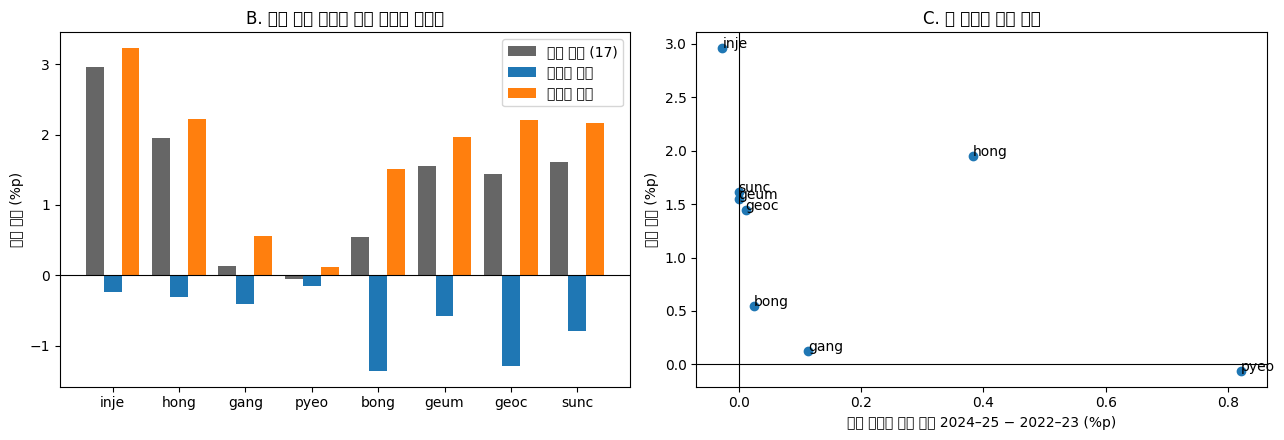

저장: /content/drive/MyDrive/forest/outputs/exp18.png  (한글 글자가 네모로 보여도 숫자 판정에는 영향 없음)


In [11]:
# [9] 그림 → exp18.png
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
x = np.arange(nr); w = 0.27
ax[0].bar(x - w, DF.mean(0), w, label='가짜 변화 (17)', color='0.4')
ax[0].bar(x,     DX['W_a'].mean(0), w, label='겨울만 바꿈', color='tab:blue')
ax[0].bar(x + w, DX['S_a'].mean(0), w, label='여름만 바꿈', color='tab:orange')
ax[0].axhline(0, color='k', lw=0.8)
ax[0].set_xticks(x); ax[0].set_xticklabels([r[:4] for r in TRAIN_REGIONS])
ax[0].set_ylabel('탄소 차이 (%p)'); ax[0].legend(); ax[0].set_title('B. 어느 계절 사진이 가짜 변화를 만드나')
if 'CT' in globals() and len(CT) == nr:
    ax[1].scatter(CT['눈우세_차_%p'], DH_MEAN)
    for j, r in enumerate(TRAIN_REGIONS):
        ax[1].annotate(r[:4], (CT['눈우세_차_%p'].iloc[j], DH_MEAN[j]))
    ax[1].axvline(0, color='k', lw=0.8); ax[1].axhline(0, color='k', lw=0.8)
    ax[1].set_xlabel('겨울 눈우세 픽셀 차이 2024–25 − 2022–23 (%p)'); ax[1].set_ylabel('가짜 변화 (%p)')
    ax[1].set_title('C. 눈 차이와 가짜 변화')
plt.tight_layout(); plt.savefig(f'{OUT}/exp18.png', dpi=120); plt.show()
print('저장:', f'{OUT}/exp18.png  (한글 글자가 네모로 보여도 숫자 판정에는 영향 없음)')